# Práctica 5. Puertas cuánticas de un qubit con Qiskit

## Información general

**Asignatura:** Computación cuántica  
**Sesión:** 5  
**Título:** Puertas cuánticas de un qubit   
**Modalidad:** Individual  
**Entorno recomendado:** Jupyter Notebook  
**Bibliotecas:** NumPy, Matplotlib, Qiskit y Qiskit Aer

## Objetivos

En esta práctica vas a trabajar con puertas cuánticas de un qubit desde dos puntos de vista:

- Como matrices aplicadas a vectores de estado.
- Como operaciones dentro de circuitos de Qiskit.

Al finalizar la práctica deberás ser capaz de:

- Definir puertas cuánticas como matrices unitarias.
- Aplicar puertas a estados de un qubit usando NumPy.
- Reproducir las mismas operaciones con Qiskit.
- Obtener el vector de estado resultante con `Statevector`.
- Calcular probabilidades de medida.
- Distinguir puertas que modifican probabilidades de puertas que modifican fase.
- Analizar el efecto del orden de aplicación de las puertas.
- Simular medidas y comparar probabilidades teóricas con conteos experimentales.

## Entrega

Entrega este notebook completado con:

- Código ejecutado.
- Resultados visibles.
- Tablas completadas cuando se soliciten.
- Gráficas generadas.
- Respuestas razonadas en las celdas indicadas.
- Conclusión final.

## 1. Preparación del entorno

Ejecuta la siguiente celda para importar las bibliotecas necesarias.

In [60]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

SEMILLA = 42

## 2. Parte A. Puertas como matrices

### Ejercicio 1. Estados de la base computacional

Define con NumPy los estados:

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix}
$$

$$
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}
$$

Utiliza explícitamente `dtype=complex`.

In [61]:
# TODO: define los estados de la base computacional
ket_0 = np.array([1,0], dtype=complex)
ket_1 = np.array([0,1], dtype=complex)

print("|0> =", ket_0)
print("|1> =", ket_1)

print("Norma de |0>:", np.linalg.norm(ket_0))
print("Norma de |1>:", np.linalg.norm(ket_1))

|0> = [1.+0.j 0.+0.j]
|1> = [0.+0.j 1.+0.j]
Norma de |0>: 1.0
Norma de |1>: 1.0


**Responde:**

1. ¿Qué representa cada componente del vector?
2. ¿Por qué la norma debe ser 1?
3. ¿Por qué usamos `dtype=complex`?

Respuesta:

1. Cada componente del vector es la amplitud compleja del estado base correspondiente: la primera de $|0\rangle$ y la segunda de $|1\rangle$. Su módulo al cuadrado da la probabilidad de medir ese resultado.
2. La norma debe ser 1 para que la suma de las probabilidades de todos los resultados sea 1.
3. Usamos dtype=complex porque las amplitudes pueden tener parte imaginaria y las puertas cuánticas, como Y, S y T, introducen fases complejas.

### Ejercicio 2. Definición de puertas básicas

Define con NumPy las matrices de las siguientes puertas:

$$
I =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}
$$

$$
X =
\begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
$$

$$
Y =
\begin{pmatrix}
0 & -i \\
i & 0
\end{pmatrix}
$$

$$
Z =
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
$$

$$
H =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

In [62]:
# TODO: define las matrices de las puertas
I = np.matrix('1 0;0 1', dtype=complex)
X = np.matrix('0 1;1 0', dtype=complex)
Y = np.matrix('0 -1j;1j 0', dtype=complex)
Z = np.matrix('1 0;0 -1', dtype=complex)
H = (1/np.sqrt(2))*np.matrix('1 1;1 -1', dtype=complex)

puertas_basicas = {
    "I": I,
    "X": X,
    "Y": Y,
    "Z": Z,
    "H": H,
}
for nombre, puerta in puertas_basicas.items():
    print(f"{nombre} =")
    print(puerta)
    print()

I =
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Y =
[[ 0.+0.j -0.-1.j]
 [ 0.+1.j  0.+0.j]]

Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

H =
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]



**Responde:**

1. ¿Qué dimensión tiene cada matriz?
2. ¿Por qué una puerta de un qubit se representa con una matriz 2 x 2?
3. ¿Qué diferencia observas entre las puertas X, Y y Z?

Respuesta:

1. Todas las matrices son de dimensión 2 × 2.
2. Un qubit tiene dos estados de la base computacional, $|0\rangle$ y $|1\rangle$; por eso su vector tiene dos componentes y una transformación lineal sobre él se representa con una matriz 2 × 2.
3. X intercambia $|0\rangle$ y $|1\rangle$; Y también los intercambia, pero introduce factores $i$ y $-i$; Z no intercambia los estados, sino que cambia el signo de la amplitud de $|1\rangle$.

### Ejercicio 3. Comprobación de unitariedad

Implementa una función que compruebe si una matriz es unitaria:

$$
U^\dagger U = I
$$

Recuerda que $U^\dagger$ es la traspuesta conjugada de U.

In [63]:
def es_unitaria(U, tolerancia=1e-10):
    """Comprueba si una matriz es unitaria."""
    U = np.asarray(U, dtype=complex)

    # Solo pueden ser unitarias las matrices cuadradas.
    if U.ndim != 2 or U.shape[0] != U.shape[1]:
        return False

    identidad = np.eye(U.shape[0], dtype=complex)
    producto = U.conj().T @ U
    return bool(np.allclose(producto, identidad, atol=tolerancia, rtol=0))


In [64]:
# TODO: comprueba la unitariedad de las puertas 
for nombre, puerta in puertas_basicas.items():
    print(nombre, es_unitaria(puerta))

I True
X True
Y True
Z True
H True


Completa la tabla:

| Puerta | ¿Es unitaria? |
|---|---:|
| I | Sí |
| X | Sí |
| Y | Sí |
| Z | Sí |
| H | Sí |

**Responde:**

1. ¿Son unitarias todas las puertas anteriores?
2. ¿Qué propiedad del estado garantiza la unitariedad?
3. ¿Por qué una puerta cuántica debe ser reversible?

Respuesta: 
1. Sí. I, X, Y, Z y H son unitarias: todas cumplen $U^\dagger U=I$.
2. La unitariedad conserva la norma del vector de estado y, por tanto, la suma de las probabilidades.
3. Porque en la evolución de un sistema cuántico cerrado la operación debe poder deshacerse: la inversa de una puerta unitaria es su adjunta, $U^{-1}=U^\dagger$.

## 3. Parte B. Aplicación de puertas con NumPy

### Ejercicio 4. Función para calcular probabilidades

Implementa una función que devuelva las probabilidades de medir 0 y 1 en la base computacional.

In [65]:
def probabilidades(estado):
    '''
    Devuelve las probabilidades de medir 0 y 1.
    '''
    # TODO: convierte el estado a array complejo
    estado = estado.astype(complex).flatten()
    # TODO: calcula el módulo al cuadrado de cada amplitud
    probs = np.abs(estado) ** 2

    return {
        0: float(probs[0]),
        1: float(probs[1]),
    }


### Ejercicio 5. Aplicar puertas a $|0\rangle$

Aplica las puertas I, X, Y, Z y H al estado $|0\rangle$.

In [66]:
resultados_ket0 = {}

estado_0 = np.array([1,0], dtype= complex)
for nombre, puerta in puertas_basicas.items():
    # TODO: aplica la puerta al estado |0>
    estado_final = np.asarray(puerta) @ estado_0
    resultados_ket0[nombre] = estado_final

    print(f"{nombre}|0> = {resultados_ket0[nombre]}")
    print("Probabilidades:", probabilidades(estado_final))
    print()

I|0> = [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

X|0> = [0.+0.j 1.+0.j]
Probabilidades: {0: 0.0, 1: 1.0}

Y|0> = [0.+0.j 0.+1.j]
Probabilidades: {0: 0.0, 1: 1.0}

Z|0> = [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

H|0> = [0.70710678+0.j 0.70710678+0.j]
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}



Completa la tabla:

| Puerta | Estado resultante | Probabilidad de 0 | Probabilidad de 1 |
|---|---|---:|---:|
| I | $\|0\rangle$ | 1 | 0 |
| X | $\|1\rangle$ | 0 | 1 |
| Y | $i\|1\rangle$ | 0 | 1 |
| Z | $\|0\rangle$ | 1 | 0 |
| H | $(\|0\rangle+\|1\rangle)/\sqrt{2}$ | 0,5 | 0,5 |

**Responde:**

1. ¿Qué puertas cambian las probabilidades al aplicarse sobre $|0\rangle$?
2. ¿Qué puertas no cambian las probabilidades?
3. ¿Qué diferencia hay entre $X|0\rangle$ e $Y|0\rangle$?
4. ¿Se puede distinguir esa diferencia midiendo directamente en la base computacional?

Respuesta:

1. X, Y y H cambian las probabilidades respecto a medir directamente $|0\rangle$.
2. I y Z mantienen $P(0)=1$ y $P(1)=0$.
3. $X|0\rangle=|1\rangle$, mientras que $Y|0\rangle=i|1\rangle$. Solo difieren en una fase global $i$ para este estado.
4. No. Al medir directamente en la base computacional ambos dan 1 con probabilidad 1; la fase global no es observable.

### Ejercicio 6. Aplicar puertas a $|1\rangle$

Repite el ejercicio anterior aplicando las mismas puertas a $|1\rangle$.

In [67]:
resultados_ket1 = {}

estado_1 = np.array([0,1], dtype= complex)
for nombre, puerta in puertas_basicas.items():
    # TODO: aplica la puerta al estado |1>
    estado_final = np.asarray(puerta) @ estado_1
    resultados_ket1[nombre] = estado_final

    print(f"{nombre}|1> = {estado_final}")
    print("Probabilidades:", probabilidades(estado_final))
    print()

I|1> = [0.+0.j 1.+0.j]
Probabilidades: {0: 0.0, 1: 1.0}

X|1> = [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

Y|1> = [0.-1.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

Z|1> = [ 0.+0.j -1.+0.j]
Probabilidades: {0: 0.0, 1: 1.0}

H|1> = [ 0.70710678+0.j -0.70710678+0.j]
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}



Completa la tabla:

| Puerta | Estado resultante | Probabilidad de 0 | Probabilidad de 1 |
|---|---|---:|---:|
| I | $\|1\rangle$ | 0 | 1 |
| X | $\|0\rangle$ | 1 | 0 |
| Y | $-i\|0\rangle$ | 1 | 0 |
| Z | $-\|1\rangle$ | 0 | 1 |
| H | $(\|0\rangle-\|1\rangle)/\sqrt{2}$ | 0,5 | 0,5 |

**Responde:**

1. ¿Qué resultado produce $X|1\rangle$?
2. ¿Qué resultado produce $Z|1\rangle$?
3. ¿Son físicamente distinguibles $|1\rangle$ y $-|1\rangle$ mediante una medida directa?
4. ¿Qué estado produce $H|1\rangle$?

Respuesta:

1. $X|1\rangle=|0\rangle$: cambia el valor del qubit.
2. $Z|1\rangle=-|1\rangle$: añade un signo negativo a la amplitud.
3. No. $|1\rangle$ y $-|1\rangle$ solo difieren en una fase global, así que producen el mismo resultado en una medida directa.
4. $H|1\rangle=(|0\rangle-|1\rangle)/\sqrt{2}=|-\rangle$, con probabilidad 0,5 para cada resultado.

### Ejercicio 7. Estados $|+\rangle$ y $|-\rangle$

Define los estados:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

$$
|-\rangle =
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

In [68]:
# TODO: define |+> y |->
ket_plus = np.array([1/np.sqrt(2),1/np.sqrt(2)], dtype=complex)
ket_minus = np.array([1/np.sqrt(2),-1/np.sqrt(2)], dtype=complex)

print("|+> =", ket_plus)
print("|-> =", ket_minus)

print("Norma |+>:", np.linalg.norm(ket_plus))
print("Norma |->:", np.linalg.norm(ket_minus))

print("Probabilidades |+>:", probabilidades(ket_plus))
print("Probabilidades |->:", probabilidades(ket_minus))

|+> = [0.70710678+0.j 0.70710678+0.j]
|-> = [ 0.70710678+0.j -0.70710678+0.j]
Norma |+>: 0.9999999999999999
Norma |->: 0.9999999999999999
Probabilidades |+>: {0: 0.4999999999999999, 1: 0.4999999999999999}
Probabilidades |->: {0: 0.4999999999999999, 1: 0.4999999999999999}


**Responde:**

1. ¿Tienen las mismas probabilidades en la base computacional?
2. ¿Son el mismo estado?
3. ¿Qué diferencia hay entre ellos?
4. ¿Qué concepto aparece aquí?

Respuesta:

1. Sí. Tanto $|+\rangle$ como $|-\rangle$ tienen $P(0)=P(1)=0,5$.
2. No, son estados diferentes y, de hecho, ortogonales.
3. En $|+\rangle$ ambas amplitudes tienen el mismo signo; en $|-\rangle$ la amplitud de $|1\rangle$ tiene signo opuesto, es decir, hay una fase relativa de $\pi$.
4. Aparece el concepto de fase relativa y su relación con la interferencia cuántica.

## 4. Parte C. Las mismas puertas con Qiskit

### Ejercicio 8. Puerta X en Qiskit

Crea un circuito de un qubit que aplique una puerta X, dibújalo y obtén su vector de estado.

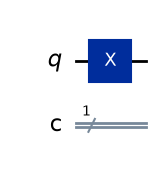

<IPython.core.display.Latex object>

Vector de estado: [0.+0.j 1.+0.j]
{np.str_('1'): np.float64(1.0)}


In [69]:
# TODO: crea un circuito de un qubit con una puerta X
qc = QuantumCircuit(1,1)
qc.x(0)

display(qc.draw("mpl"))

estado = Statevector.from_instruction(qc)
display(estado.draw("latex"))
print("Vector de estado:", estado.data)
print(estado.probabilities_dict())

**Responde:**

1. ¿Cuál es el estado inicial por defecto en Qiskit?
2. ¿Qué estado se obtiene después de aplicar \(X\)?
3. ¿Coincide con el cálculo hecho con NumPy?

Respuesta:

1. El estado inicial de un qubit en Qiskit es $|0\rangle$.
2. Al aplicar X se obtiene $|1\rangle$, cuyo vector es $(0,1)$.
3. Sí. Coincide con $X|0\rangle=|1\rangle$ calculado mediante la matriz X de NumPy

### Ejercicio 9. Función auxiliar para analizar circuitos

Completa la función `analizar_circuito`.

In [70]:
def analizar_circuito(qc):
    '''
    Dibuja un circuito, muestra su Statevector y devuelve sus probabilidades.
    '''
    # TODO: obtiene el vector de estado
    estado = Statevector.from_instruction(qc)

    display(qc.draw("mpl"))
    display(estado.draw("latex"))

    probs = estado.probabilities_dict()
    print(probs)

    return estado, probs

### Ejercicio 10. Puertas I, X, Y, Z y H en Qiskit

Crea un circuito independiente para cada una de las puertas:

- `id`
- `x`
- `y`
- `z`
- `h`

Todas deben aplicarse sobre el estado inicial $|0\rangle$.

Puerta: X


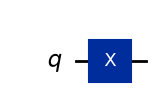

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(1.0)}

Puerta: id


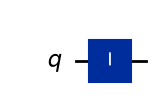

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta: Y


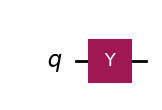

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(1.0)}

Puerta: Z


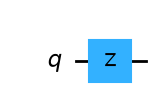

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta: H


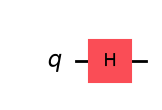

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}



In [71]:
circuitos_qiskit = {}

# TODO: crea los circuitos y guárdalos en el diccionario circuitos_qiskit

# Ejemplo:
qc_x = QuantumCircuit(1)
qc_x.x(0)
circuitos_qiskit["X"] = qc_x

qc_id = QuantumCircuit(1)
qc_id.id(0)
circuitos_qiskit["id"] = qc_id

qc_y = QuantumCircuit(1)
qc_y.y(0)
circuitos_qiskit["Y"] = qc_y

qc_z = QuantumCircuit(1)
qc_z.z(0)
circuitos_qiskit["Z"] = qc_z

qc_h = QuantumCircuit(1)
qc_h.h(0)
circuitos_qiskit["H"] = qc_h

for nombre, circuito in circuitos_qiskit.items():
    print("Puerta:", nombre)
    analizar_circuito(circuito)
    print()

**Responde:**

1. ¿Qué puertas producen cambios visibles en las probabilidades?
2. ¿Qué puertas producen cambios de fase?
3. ¿Qué información muestra `Statevector` que no aparece en un histograma?

Respuesta:

1. Partiendo de $|0\rangle$, X e Y hacen que el resultado sea 1 con certeza, y H crea una distribución de 0,5 y 0,5. I y Z no cambian esas probabilidades.
2. Y introduce una fase (sobre $|0\rangle$, un factor global $i$). Z cambia la fase de la componente $|1\rangle$, aunque ese cambio no se aprecia si el estado inicial es $|0\rangle$.
3. Statevector muestra las amplitudes complejas, incluidos sus signos y fases. Un histograma solo muestra frecuencias o probabilidades, sin esa información de fase.

## 5. Parte D. Puertas de fase

### Ejercicio 11. Puertas S y T con NumPy

Define con NumPy las puertas:

$$
S =
\begin{pmatrix}
1 & 0 \\
0 & i
\end{pmatrix}
$$

$$
T =
\begin{pmatrix}
1 & 0 \\
0 & e^{i\pi/4}
\end{pmatrix}
$$

In [72]:
# TODO: define S y T
S = np.array([[1, 0],[0, 1j]], dtype=complex)
T = np.array([[1, 0],[0, np.exp(1j * np.pi / 4)]], dtype=complex)


print("S =")
print(S)
print()
print("T =")
print(T)

print("S unitaria:", es_unitaria(S))
print("T unitaria:", es_unitaria(T))

S =
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]

T =
[[1.        +0.j         0.        +0.j        ]
 [0.        +0.j         0.70710678+0.70710678j]]
S unitaria: True
T unitaria: True


In [73]:
estados_para_fase = {
    "|0>": ket_0,
    "|1>": ket_1,
    "|+>": ket_plus,
}

puertas_fase = {
    "S": S,
    "T": T,
}

for nombre_puerta, puerta in puertas_fase.items():
    for nombre_estado, estado_inicial in estados_para_fase.items():
        # TODO: aplica la puerta al estado inicial
        estado_final = puerta@estado_inicial
        print(f"{nombre_puerta} sobre {nombre_estado}: {estado_final}")
        print("Probabilidades:", probabilidades(estado_final))
        print()

S sobre |0>: [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

S sobre |1>: [0.+0.j 0.+1.j]
Probabilidades: {0: 0.0, 1: 1.0}

S sobre |+>: [0.70710678+0.j         0.        +0.70710678j]
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}

T sobre |0>: [1.+0.j 0.+0.j]
Probabilidades: {0: 1.0, 1: 0.0}

T sobre |1>: [0.        +0.j         0.70710678+0.70710678j]
Probabilidades: {0: 0.0, 1: 1.0000000000000004}

T sobre |+>: [0.70710678+0.j  0.5       +0.5j]
Probabilidades: {0: 0.4999999999999999, 1: 0.5000000000000001}



Completa la tabla:

| Puerta | Estado inicial | Estado final | Probabilidades |
|---|---|---|---|
| S | $\|0\rangle$ | $\|0\rangle$ | (1, 0) |
| S | $\|1\rangle$ | $i\|1\rangle$ | (0, 1) |
| S | $\|+\rangle$ | $(\|0\rangle+i\|1\rangle)/\sqrt{2}$ | (0,5; 0,5) |
| T | $\|0\rangle$ | $\|0\rangle$ | (1, 0) |
| T | $\|1\rangle$ | $e^{i\pi/4}\|1\rangle$ | (0, 1) |
| T | $\|+\rangle$ | $(\|0\rangle+e^{i\pi/4}\|1\rangle)/\sqrt{2}$ | (0,5; 0,5) |


**Responde:**

1. ¿Cambian las probabilidades al aplicar S o T sobre $|0\rangle$?
2. ¿Cambian las probabilidades al aplicarlas sobre $|1\rangle$?
3. ¿Qué cambia realmente?
4. ¿Por qué es importante la fase relativa?

Respuesta:
1. No. S y T dejan $|0\rangle$ igual, así que $P(0)=1$.
2. Tampoco. Sobre $|1\rangle$ añaden una fase, pero sigue siendo seguro medir 1.
3. Cambian la fase de la amplitud asociada a $|1\rangle$: S introduce $\pi/2$ y T introduce $\pi/4$. Cuando hay superposición, cambia la fase relativa entre las dos componentes.
4. La fase relativa influye en cómo interfieren las amplitudes cuando se aplican otras puertas; por ello puede acabar produciendo diferencias en las probabilidades.

### Ejercicio 12. Puertas S y T en Qiskit

Reproduce el ejercicio anterior con Qiskit preparando primero $|+\rangle$ y aplicando después `s` o `t`.

Circuito H + S


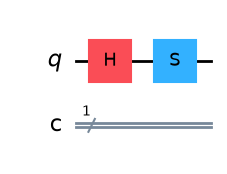

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Circuito H + T


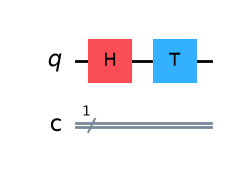

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [74]:
qc = QuantumCircuit(1,1)
qc.h(0)
# Circuito H + S
qc_s = qc.copy()
qc_s.s(0)

# Circuito H + T
qc_t = qc.copy()
qc_t.t(0)

print("Circuito H + S")
estado_s, probs_s = analizar_circuito(qc_s)

print("Circuito H + T")
estado_t, probs_t = analizar_circuito(qc_t)

**Responde:**

1. ¿Coinciden los resultados con NumPy?
2. ¿Qué diferencia hay entre `s` y `t`?
3. ¿Puede una puerta cambiar el estado sin cambiar las probabilidades de medida en la base computacional?

Respuesta:

1. Sí. Para $|+\rangle$, Qiskit y NumPy dan las mismas amplitudes y probabilidades, salvo pequeños errores de redondeo.
2. S introduce una fase de $\pi/2$ sobre la componente $|1\rangle$, mientras que T introduce $\pi/4$. Por eso $S=T^2$.
3. Sí. Estas puertas modifican la fase relativa del estado, pero mantienen las probabilidades de medida en la base computacional.

## 6. Parte E. Fase relativa e interferencia

### Ejercicio 13. Comparación entre $|+\rangle$ y $|-\rangle$

Crea dos circuitos.

Circuito A:

```python
qc_a = QuantumCircuit(1)
qc_a.h(0)
```

Circuito B:

```python
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)
```

Circuito A


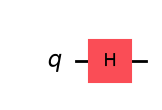

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Circuito B


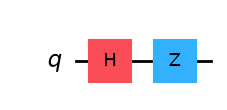

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [75]:
# TODO: crea el circuito A
qc_a = QuantumCircuit(1)
qc_a.h(0)

# TODO: crea el circuito B
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)

print("Circuito A")
estado_a, probs_a = analizar_circuito(qc_a)

print("Circuito B")
estado_b, probs_b = analizar_circuito(qc_b)

**Responde:**

1. ¿Qué estado prepara el circuito A?
2. ¿Qué estado prepara el circuito B?
3. ¿Tienen las mismas probabilidades?
4. ¿Son el mismo estado?
5. ¿Qué diferencia hay entre ellos?

Respuesta:

1. El circuito A prepara $|+\rangle=(|0\rangle+|1\rangle)/\sqrt{2}$.
2. El circuito B prepara $|-\rangle=(|0\rangle-|1\rangle)/\sqrt{2}$.
3. Sí. Ambos tienen $P(0)=P(1)=0,5$.
4. No. Son estados distintos.
5. Tienen distinta fase relativa: en B la amplitud de $|1\rangle$ tiene signo negativo, y en A no.

### Ejercicio 14. Convertir fase en probabilidad

Añade una puerta H al final de los dos circuitos anteriores.

Circuito A:

```python
qc_a = QuantumCircuit(1)
qc_a.h(0)
qc_a.h(0)
```

Circuito B:

```python
qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.z(0)
qc_b.h(0)
```

Circuito A final


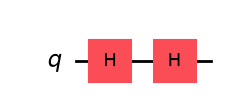

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}
Circuito B final


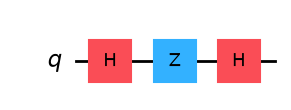

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(0.9999999999999996)}


In [76]:
# TODO: circuito A con H final
qc_a_final = qc_a.copy()
qc_a_final.h(0)

# TODO: circuito B con H final
qc_b_final = qc_b.copy()
qc_b_final.h(0)

print("Circuito A final")
estado_a_final, probs_a_final = analizar_circuito(qc_a_final)

print("Circuito B final")
estado_b_final, probs_b_final = analizar_circuito(qc_b_final)

Completa la tabla:

| Circuito | Estado antes de la última H | Estado final | P(0) | P(1) |
|---|---|---|---:|---:|
| A | $\|+\rangle$ | $\|0\rangle$ | 1 | 0 |
| B | $\|-\rangle$ | $\|1\rangle$ | 0 | 1 |

**Responde:**

1. ¿Qué resultado produce el circuito A?
2. ¿Qué resultado produce el circuito B?
3. ¿Por qué ahora sí aparece una diferencia en las probabilidades?
4. ¿Qué relación tiene esto con la interferencia cuántica?

Respuesta:

1. El circuito A, si incluye la H final indicada en el enunciado, produce $|0\rangle$, por lo que se mide 0 con certeza.
2. El circuito B, si incluye esa H final, produce $|1\rangle$, por lo que se mide 1 con certeza.
3. La última H combina las amplitudes de forma distinta dependiendo de su signo: la fase relativa pasa a convertirse en una diferencia de probabilidades.
4. Es un ejemplo de interferencia cuántica: las amplitudes pueden sumarse o cancelarse.

## 7. Parte F. Composición y orden de puertas

### Ejercicio 15. Comparación de órdenes

Crea dos circuitos:

Circuito 1:

```python
qc1 = QuantumCircuit(1)
qc1.h(0)
qc1.z(0)
```

Circuito 2:

```python
qc2 = QuantumCircuit(1)
qc2.z(0)
qc2.h(0)
```

Circuito 1: H y después Z


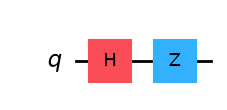

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Circuito 2: Z y después H


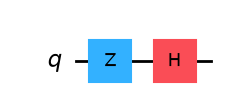

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [77]:
# TODO: crea ambos circuitos
qc1 = QuantumCircuit(1)
qc1.h(0)
qc1.z(0)

qc2 = QuantumCircuit(1)
qc2.z(0)
qc2.h(0)

print("Circuito 1: H y después Z")
estado_1, probs_1 = analizar_circuito(qc1)

print("Circuito 2: Z y después H")
estado_2, probs_2 = analizar_circuito(qc2)

**Responde:**

1. ¿Son iguales los estados finales?
2. ¿Son iguales las probabilidades?
3. ¿Por qué puede ocurrir que los estados sean distintos pero las probabilidades iguales?
4. ¿Importa el orden de aplicación de puertas?
5. ¿Qué significa que dos puertas no conmuten?

Respuesta:

1. No. H seguida de Z produce $|-\rangle$, mientras que Z seguida de H produce $|+\rangle$ al partir de $|0\rangle$.
2. Sí. En ambos casos, $P(0)=P(1)=0,5$.
3. Porque la medida en la base computacional depende del módulo al cuadrado de las amplitudes y no revela su fase relativa.
4. Sí. Aplicar las mismas puertas en otro orden puede producir un estado final distinto.
5. Dos puertas no conmutan si $AB\neq BA$: cambiar su orden cambia, en general, la transformación realizada.

### Ejercicio 16. Comprobación matricial del orden

Calcula con NumPy:

$$
ZH|0\rangle
$$

y:

$$
HZ|0\rangle
$$

In [78]:
# TODO: calcula ambos estados con NumPy
estado_1_numpy = Z @ H @ estado_0
estado_2_numpy = H @ Z @ estado_0

print("ZH|0> =", estado_1_numpy)
print("HZ|0> =", estado_2_numpy)

ZH|0> = [[ 0.70710678+0.j -0.70710678+0.j]]
HZ|0> = [[0.70710678+0.j 0.70710678+0.j]]


**Responde:**

1. ¿Coinciden NumPy y Qiskit?
2. ¿Qué operación se aplica primero en la expresión $ZH|0\rangle$?
3. ¿Cómo se relaciona el orden matricial con el orden visual del circuito?

Respuesta:

1. Sí. NumPy da $ZH|0\rangle=|-\rangle$ y $HZ|0\rangle=|+\rangle$, los mismos estados que los dos circuitos de Qiskit.
2. En $ZH|0\rangle$ se aplica primero H al estado y después Z.
3. En el producto de matrices se actúa de derecha a izquierda; en el dibujo del circuito las puertas se ejecutan normalmente de izquierda a derecha.

## 8. Parte G. Puertas inversas

### Ejercicio 17. Puertas que son su propia inversa

Comprueba con Qiskit que las siguientes puertas aplicadas dos veces devuelven el estado inicial:

- X
- Y
- Z
- H

Puerta X aplicada dos veces


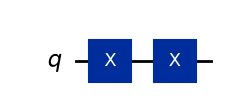

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta Y aplicada dos veces


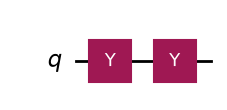

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta Z aplicada dos veces


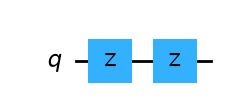

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

Puerta H aplicada dos veces


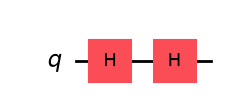

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}



In [79]:
puertas_dos_veces = ["x", "y", "z", "h"]

for nombre in puertas_dos_veces:
    qc = QuantumCircuit(1)

    # TODO: aplica dos veces la puerta indicada por nombre
    getattr(qc, nombre)(0)
    getattr(qc, nombre)(0)


    print(f"Puerta {nombre.upper()} aplicada dos veces")
    estado, probs = analizar_circuito(qc)
    print()

Completa la tabla:

| Puerta aplicada dos veces | Estado final |
|---|---|
| X | $\|0\rangle$ |
| Y | $\|0\rangle$ |
| Z | $\|0\rangle$ |
| H | $\|0\rangle$ |

**Responde:**

1. ¿Qué tienen en común estas puertas?
2. ¿Qué significa que una puerta sea su propia inversa?
3. ¿Se cumple exactamente o aparece alguna fase global en algún caso?

Respuesta:

1. Todas son autoinversas: aplicar cada una dos veces equivale a la identidad.
2. Significa que la propia puerta deshace su efecto, es decir, $U^{-1}=U$ y $U^2=I$.
3. En estos cuatro casos el estado vuelve a $|0\rangle$ sin una fase global adicional. En H pueden aparecer diferencias mínimas de redondeo al trabajar numéricamente

### Ejercicio 18. Inversas de S y T

Crea los siguientes circuitos:

```python
qc_s = QuantumCircuit(1)
qc_s.h(0)
qc_s.s(0)
qc_s.sdg(0)
```

```python
qc_t = QuantumCircuit(1)
qc_t.h(0)
qc_t.t(0)
qc_t.tdg(0)
```

S seguida de Sdg


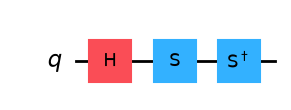

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
T seguida de Tdg


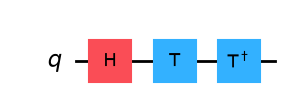

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999998)}


In [80]:
qc_s = QuantumCircuit(1)
# TODO: circuito con S y su inversa
qc_s.h(0)
qc_s.s(0)
qc_s.sdg(0)

qc_s_inv = qc_s


qc_t = QuantumCircuit(1)
# TODO: circuito con T y su inversa
qc_t.h(0)
qc_t.t(0)
qc_t.tdg(0)

qc_t_inv = qc_t



print("S seguida de Sdg")
estado_s_inv, probs_s_inv = analizar_circuito(qc_s_inv)

print("T seguida de Tdg")
estado_t_inv, probs_t_inv = analizar_circuito(qc_t_inv)

**Responde:**

1. ¿Qué hace `sdg`?
2. ¿Qué hace `tdg`?
3. ¿Por qué el estado final vuelve a coincidir con el estado anterior a aplicar `s` o `t`?
4. ¿Qué relación tiene esto con la reversibilidad?

Respuesta:

1. sdg es la adjunta o inversa de S: añade una fase de $-\pi/2$ a la amplitud de $|1\rangle$.
2. tdg es la adjunta o inversa de T: añade una fase de $-\pi/4$ a esa amplitud.
3. Porque las fases añadidas por S y T se cancelan al aplicar sus respectivas inversas, de manera que $S^\dagger S=T^\dagger T=I$.
4. Muestra que las puertas cuánticas unitarias son reversibles y se pueden deshacer aplicando la puerta inversa.

## 9. Parte H. Rotaciones

### Ejercicio 19. Rotación $R_y(\theta)$

Crea circuitos que apliquen $R_y(\theta)$ sobre $|0\rangle$ para los siguientes valores:

$$
\theta = 0,\ \frac{\pi}{4},\ \frac{\pi}{2},\ \pi
$$

theta = 0


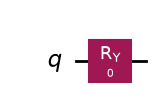

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(1.0)}

theta = 0.7853981633974483


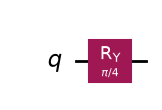

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.8535533905932737), np.str_('1'): np.float64(0.14644660940672624)}

theta = 1.5707963267948966


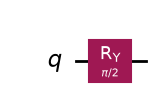

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.5000000000000001), np.str_('1'): np.float64(0.5000000000000001)}

theta = 3.141592653589793


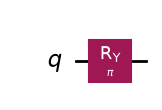

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(3.749399456654644e-33), np.str_('1'): np.float64(1.0)}



In [81]:
angulos = [0, np.pi / 4, np.pi / 2, np.pi]
resultados_ry = []

for theta in angulos:
    qc = QuantumCircuit(1)

    # Aplica Ry(theta) al qubit 0
    qc.ry(theta, 0)

    estado = Statevector.from_instruction(qc)
    probs = estado.probabilities_dict()

    resultados_ry.append((theta, estado, probs))

    print("theta =", theta)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(probs)
    print()

Completa la tabla:

| $\theta$ | Estado aproximado | P(0) | P(1) |
|---:|---|---:|---:|
| 0 | $\|0\rangle$ | 1 | 0 |
| $\pi/4$ | $0{,}9239\|0\rangle+0{,}3827\|1\rangle$ | 0,8536 | 0,1464 |
| $\pi/2$ | $(\|0\rangle+\|1\rangle)/\sqrt{2}$ | 0,5 | 0,5 |
| $\pi$ | $\|1\rangle$ | 0 | 1 |

**Responde:**

1. ¿Qué ocurre cuando aumenta $\theta$?
2. ¿Qué valor de $\theta$ produce una superposición equilibrada?
3. ¿Qué valor de $\theta$ lleva aproximadamente de $|0\rangle$ a $|1\rangle$?
4. ¿Por qué las rotaciones son útiles?

Respuesta:

1. Al aumentar $\theta$ de 0 a $\pi$, la amplitud y probabilidad de $|1\rangle$ aumentan mientras que las de $|0\rangle$ disminuyen: $R_y(\theta)|0\rangle=\cos(\theta/2)|0\rangle+\sin(\theta/2)|1\rangle$.
2. $\theta=\pi/2$ produce una superposición equilibrada.
3. $\theta=\pi$ transforma $|0\rangle$ en $|1\rangle$ (salvo precisión numérica).
4. Las rotaciones permiten controlar de forma continua las amplitudes y probabilidades del qubit, no solo cambiar entre estados concretos.

### Ejercicio 20. Rotación $R_z(\theta)$)

Crea circuitos que preparen primero $|+\rangle$ y después apliquen $R_z(\theta)$:

```python
qc = QuantumCircuit(1)
qc.h(0)
qc.rz(theta, 0)
```

Utiliza:

$$
\theta = 0,\ \frac{\pi}{2},\ \pi
$$

theta = 0


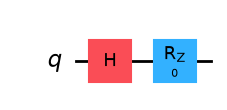

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

theta = 1.5707963267948966


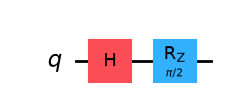

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.5000000000000001), np.str_('1'): np.float64(0.5000000000000001)}

theta = 3.141592653589793


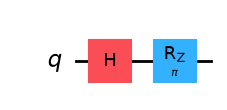

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}



In [82]:
angulos_rz = [0, np.pi / 2, np.pi]
resultados_rz = []

for theta in angulos_rz:
    qc = QuantumCircuit(1)
    qc.h(0)
    # TODO: prepara |+> y aplica rz(theta, 0)
    qc.rz(theta, 0)

    estado = Statevector.from_instruction(qc)
    probs = estado.probabilities_dict()

    resultados_rz.append((theta, estado, probs))

    print("theta =", theta)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(probs)
    print()

**Responde:**

1. ¿Cambian las probabilidades?
2. ¿Cambia el estado?
3. ¿Qué modifica principalmente $R_z$?
4. ¿Por qué este efecto puede no verse en un histograma de la base computacional?

Respuesta:

1. No. En los tres casos se obtiene aproximadamente $P(0)=P(1)=0,5$.
2. Sí. Las amplitudes adquieren fases distintas al variar $\theta$, aunque para $\theta=0$ el estado es el mismo.
3. $R_z$ modifica principalmente la fase relativa entre $|0\rangle$ y $|1\rangle$.
4. Porque el histograma de la base computacional solo depende de los módulos al cuadrado de las amplitudes, que no cambian por estas fases.

## 10. Parte I. Medidas y conteos

### Ejercicio 21. Medir después de aplicar puertas

Crea un circuito que prepare el estado:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

y lo mida con `shots = 1000`.

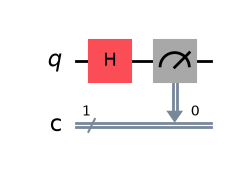

{'0': 514, '1': 486}

In [83]:
shots = 1000

# TODO: crea un circuito con un qubit y un bit clásico
qc_medida = QuantumCircuit(1,1)
qc_medida.h(0)

# TODO: prepara |+> y mide
qc_medida.measure(0, 0)

display(qc_medida.draw("mpl"))

simulador = AerSimulator(seed_simulator=SEMILLA)
qc_t = transpile(qc_medida, simulador)

resultado = simulador.run(qc_t, shots=shots).result()
conteos = resultado.get_counts()

conteos

**Responde:**

1. ¿Qué resultados esperas obtener?
2. ¿Coinciden exactamente con 500 y 500?
3. ¿Por qué?
4. ¿Qué diferencia hay entre probabilidades teóricas y conteos?

Respuesta:

1. Se esperan aproximadamente 500 resultados 0 y 500 resultados 1, porque $|+\rangle$ tiene probabilidades teóricas de 0,5 y 0,5.
2. No exactamente. En la ejecución guardada se obtuvieron 514 ceros y 486 unos.
3. Porque se hacen 1000 medidas independientes y existen fluctuaciones estadísticas propias del muestreo.
4. Las probabilidades teóricas son valores ideales (0,5 y 0,5); los conteos son el número de veces que aparece cada resultado en un conjunto finito de disparos.

### Ejercicio 22. Histograma de resultados

Representa los conteos del ejercicio anterior mediante un gráfico de barras.

El gráfico debe incluir:

- Título.
- Etiqueta del eje X.
- Etiqueta del eje Y.
- Valores encima de las barras.

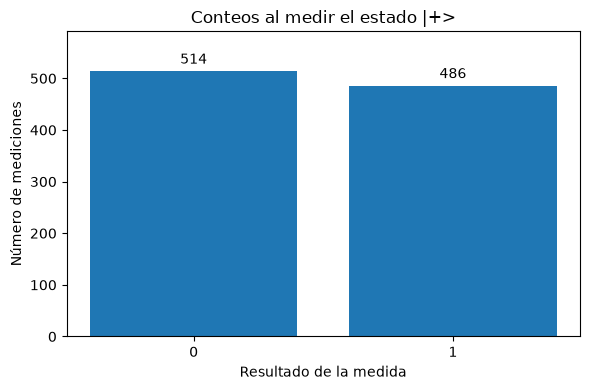

In [84]:
# Gráfico de barras con los conteos del ejercicio anterior
etiquetas = sorted(conteos.keys())
valores = [conteos[etiqueta] for etiqueta in etiquetas]

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(etiquetas, valores)

ax.set_title("Conteos al medir el estado |+>")
ax.set_xlabel("Resultado de la medida")
ax.set_ylabel("Número de mediciones")
ax.bar_label(barras, padding=3)
ax.set_ylim(0, max(valores) * 1.15)

plt.tight_layout()
plt.show()


**Responde:**

1. ¿Qué representa el histograma?
2. ¿Muestra directamente las amplitudes?
3. ¿Muestra directamente la fase?
4. ¿Qué información se pierde al medir?

Respuesta:

1. Representa cuántas veces se ha medido cada resultado clásico (0 y 1) en los 1000 disparos del circuito.
2. No. Las amplitudes son números complejos; el histograma muestra conteos asociados a sus módulos al cuadrado.
3. Tampoco. La fase del estado no se observa directamente en las barras.
4. Una medida individual proyecta el qubit sobre un resultado de la base computacional y no conserva en ese resultado la fase relativa ni la superposición original.

## 11. Reto avanzado

### Ejercicio 23. Distinguir $|+\rangle$ y $|-\rangle$ mediante una operación previa

Sabemos que $|+\rangle$ y $|-\rangle$ producen las mismas probabilidades si se miden directamente en la base computacional.

Diseña un procedimiento con Qiskit para distinguirlos.

Pista: antes de medir, aplica una puerta adecuada.

Debes construir dos circuitos:

1. Uno que prepare $|+\rangle$, aplique la operación elegida y mida.
2. Otro que prepare $|-\rangle$, aplique la operación elegida y mida.

Ejecuta ambos con `shots=1000`.

In [85]:
# TODO: circuito para preparar |+>, aplicar una operación previa y medir
qc_plus_medida = QuantumCircuit(1,1)
qc_plus_medida.h(0)
qc_plus_medida.h(0)
qc_plus_medida.measure(0, 0)

# TODO: circuito para preparar |->, aplicar una operación previa y medir
qc_minus_medida = QuantumCircuit(1, 1)
qc_minus_medida.x(0)
qc_minus_medida.h(0)       
qc_minus_medida.h(0)       
qc_minus_medida.measure(0, 0)

simulador = AerSimulator(seed_simulator=SEMILLA)

qc_plus_t = transpile(qc_plus_medida, simulador)
qc_minus_t = transpile(qc_minus_medida, simulador)

conteos_plus = simulador.run(qc_plus_t, shots=shots).result().get_counts()
conteos_minus = simulador.run(qc_minus_t, shots=shots).result().get_counts()

print("Conteos para |+>:", conteos_plus)
print("Conteos para |->:", conteos_minus)

Conteos para |+>: {'0': 1000}
Conteos para |->: {'1': 1000}


Completa la tabla:

| Estado inicial | Operación antes de medir | Resultado esperado | Conteos obtenidos |
|---|---|---|---|
| $\|+\rangle$ | H | Siempre 0 | `{"0": 1000}` |
| $\|-\rangle$ | H | Siempre 1 | `{"1": 1000}` |

**Responde:**

1. ¿Qué puerta has utilizado antes de medir?
2. ¿Por qué permite distinguir los dos estados?
3. ¿Qué resultado se obtiene para $|+\rangle$?
4. ¿Qué resultado se obtiene para $|-\rangle$?
5. ¿Qué demuestra este experimento sobre la fase relativa?

Respuesta:

1. He utilizado la puerta Hadamard (H) justo antes de medir.
2. Porque H convierte $|+\rangle$ en $|0\rangle$ y $|-\rangle$ en $|1\rangle$; así la diferencia de fase relativa se convierte en resultados distintos.
3. Para $|+\rangle$ se obtiene siempre 0: en la ejecución guardada, 1000 ceros.
4. Para $|-\rangle$ se obtiene siempre 1: en la ejecución guardada, 1000 unos.
5. Demuestra que la fase relativa tiene consecuencias físicas observables cuando se elige una operación adecuada antes de medir, aunque la medida directa en la base computacional no la revele.

## 12. Pruebas mínimas

Incluye al final del notebook las siguientes pruebas mediante `assert`.

Las pruebas deben ejecutarse sin errores cuando la práctica esté completada correctamente.

In [86]:
assert np.isclose(np.linalg.norm(ket_0), 1)
assert np.isclose(np.linalg.norm(ket_1), 1)

assert es_unitaria(I)
assert es_unitaria(X)
assert es_unitaria(Y)
assert es_unitaria(Z)
assert es_unitaria(H)
assert es_unitaria(S)
assert es_unitaria(T)

assert np.allclose(X @ ket_0, ket_1)
assert np.allclose(H @ ket_0, ket_plus)
assert np.allclose(H @ H, I)

for estado in [ket_0, ket_1, ket_plus, ket_minus]:
    probs = probabilidades(estado)
    assert np.isclose(sum(probs.values()), 1)

assert sum(conteos.values()) == shots
# Casos extra de unitariedad y coherencia de los circuitos.
assert es_unitaria(np.eye(3))
assert not es_unitaria([[1, 0], [0, 2]])
assert not es_unitaria([[1, 0, 0], [0, 1, 0]])
assert isinstance(es_unitaria(H), bool)
assert set(circuitos_qiskit.keys()) == {"id", "X", "Y", "Z", "H"}
assert np.allclose(estado_a_final.data, ket_0)
assert np.allclose(estado_b_final.data, ket_1)


## 13. Conclusión final

Redacta una conclusión de entre 150 y 250 palabras respondiendo a estas preguntas:

1. ¿Qué es una puerta cuántica de un qubit?
2. ¿Por qué las puertas cuánticas deben ser unitarias?
3. ¿Qué diferencia hay entre una puerta que cambia probabilidades y una puerta que cambia fase?
4. ¿Por qué dos estados distintos pueden producir el mismo histograma?
5. ¿Por qué el orden de las puertas importa?
6. ¿Qué has comprobado al comparar NumPy y Qiskit?

Conclusión:

Durante esta práctica he comprobado que una puerta cuántica de un qubit es una transformación que actúa sobre las dos amplitudes de su vector de estado. Se representa mediante una matriz de 2 × 2 y debe ser unitaria para conservar la norma y las probabilidades totales, además de permitir una operación inversa.
Con las puertas X, Y y H he visto cómo se pueden cambiar las probabilidades de obtener 0 o 1. En cambio, puertas como Z, S, T y Rz permiten modificar fases sin que cambien necesariamente las probabilidades al medir en la base computacional. Por eso dos estados diferentes, como $|+\rangle$ y $|-\rangle$, pueden producir el mismo histograma. La diferencia aparece al aplicar una puerta H antes de medir, ya que la fase relativa influye en la interferencia de las amplitudes.
También he observado que el orden de las puertas importa: H seguida de Z no prepara el mismo estado que Z seguida de H. Por último, la comparación entre cálculos con NumPy y simulaciones con Qiskit me ha servido para relacionar las matrices con los circuitos y entender que el vector de estado contiene información que los conteos por sí solos no muestran.